In [1]:
import time, json, warnings
from pathlib import Path
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from numpy.lib.stride_tricks import sliding_window_view as swv
from sklearn.neighbors import NearestNeighbors
import kagglehub
from kagglehub import KaggleDatasetAdapter

C:\Users\Admin\AppData\Local\anaconda3\envs\ml-projects\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
warnings.simplefilter("ignore")
plt.rcParams["figure.figsize"] = (12, 4)
sns.set_style("whitegrid")
H_MAX, N_SEG, HORIZONS, SEED = 14, 10, [1, 7, 14], 42
EMB = {"Apple": 9, "Subway": 5, "Energy": 9}           # Размерность вложения DimEmb из работы 5
LOOKBACK = {"Apple": 20, "Subway": 168, "Energy": 56}  # Окно LSTM из работы 4
SEASON = {"Apple": None, "Subway": 168, "Energy": 7}   # Период для сезонного наивного прогноза

In [3]:
from pathlib import Path

DATA_DIR = Path("data")
RESULTS_DIR = Path("results")
DATA_DIR.mkdir(exist_ok=True)
RESULTS_DIR.mkdir(exist_ok=True)

# Загрузка данных

акции Apple

In [4]:
df_apple = kagglehub.load_dataset(
    KaggleDatasetAdapter.PANDAS,
    "anukaggle81/usa-top-900-historic-dataset",
    "Apple.csv",
)
df_apple = df_apple.drop(columns=["Unnamed: 0"])
df_apple["Date"] = pd.to_datetime(df_apple["Date"])
df_apple = df_apple.sort_values("Date").reset_index(drop=True)
apple = df_apple["Close"].to_numpy(dtype=float)
print("Apple:", apple.shape)

Apple: (11156,)


MTA Subway Hourly Ridership (NYC)

In [5]:
url = "https://github.com/xinychen/integers/raw/main/Manhattan-subway/NYC_subway_mob_24.npz"
urllib.request.urlretrieve(url, DATA_DIR / "NYC_subway_mob_24.npz")
tensor = np.load(DATA_DIR / "NYC_subway_mob_24.npz")["arr_0"]
hourly_total = tensor.sum(axis=0).astype(float)
dates_sub = pd.date_range("2024-01-01", periods=len(hourly_total), freq="h")
bad = np.where(hourly_total[: 24 * 319] == 0)[0]      # 10 марта 02:00 — переход на летнее время
hourly_total[bad] = (hourly_total[bad - 1] + hourly_total[bad + 1]) / 2
print("Subway:", hourly_total.shape)

Subway: (8784,)


Потребление электроэнергии

In [6]:
energy_path = kagglehub.dataset_download("robikscube/hourly-energy-consumption")
df_energy = pd.read_csv(Path(energy_path) / "PJME_hourly.csv")
df_energy["Datetime"] = pd.to_datetime(df_energy["Datetime"])
df_energy = (df_energy.drop_duplicates(subset="Datetime")
                      .sort_values("Datetime")
                      .set_index("Datetime"))
g = df_energy["PJME_MW"].resample("D")
daily = g.mean()[g.count() >= 23]
energy = daily.to_numpy(dtype=float)
print("Energy:", energy.shape, daily.index[0].date(), "—", daily.index[-1].date())

Energy: (6058,) 2002-01-01 — 2018-08-02


In [7]:
FC_SERIES = {"Apple": apple,
             "Subway": hourly_total[: dates_sub.get_loc("2024-10-30 23:00") + 1],
             "Energy": energy}

# Протокол оценки

10 непересекающихся тестовых блоков по 14 шагов в конце ряда, горизонты 1, 7, 14, метрика MAPE, медиана по блокам. Прогноз из момента o строится только по x[:o]

Параметры методов подбираются на 30 валидационных блоках по 14 шагов, которые идут сразу перед тестовыми. Критерий подбора - среднее по горизонтам 1/7/14 от медианы MAPE. Тестовые блоки при подборе не используются

Базовые модели для сравнения:
* naive - последнее значение;
* seasonal naive - значения периода назад (метро 168 ч, энергия 7 сут)

In [8]:
def test_origins(n, n_seg=N_SEG, h=H_MAX, gap=H_MAX):
    return [n - h - gap * (n_seg - 1 - k) for k in range(n_seg)]


ORIGINS = {name: test_origins(len(x)) for name, x in FC_SERIES.items()}
N_VAL = 30
VAL = {name: test_origins(o[0], n_seg=N_VAL) for name, o in ORIGINS.items()}


def mape(y, yhat):
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    return np.mean(np.abs((y - yhat) / y)) * 100


def run(name, fc, origins):
    x = FC_SERIES[name]
    return np.array([[mape(x[o:o + h], f[:h]) for h in HORIZONS] for o in origins for f in [fc(o)]])


def score(E):
    return np.median(E, 0).mean()


def naive_fc(name):
    x = FC_SERIES[name]
    return lambda o: np.repeat(x[o - 1], H_MAX)


def snaive_fc(name):
    x, s = FC_SERIES[name], SEASON[name]
    return lambda o: x[o - s + np.arange(H_MAX) % s]


pd.DataFrame({name: {"длина": len(x), "валидация": f"{VAL[name][0]}–{VAL[name][-1] + H_MAX - 1}",
                     "тест": f"{ORIGINS[name][0]}–{ORIGINS[name][-1] + H_MAX - 1}"}
              for name, x in FC_SERIES.items()}).T

,длина,валидация,тест
Apple,11156,10596–11015,11016–11155
Subway,7296,6736–7155,7156–7295
Energy,6058,5498–5917,5918–6057


# 1. Локальная аппроксимация (А.Ю. Лоскутов)

1. Ряд вкладывается в пространство задержек размерности p (τ = 1): векторы x_s = (z_s, …, z_{s+p−1}), матрица Ганкеля
2. Для текущего состояния (последние p значений) ищутся m ближайших соседей по евклидовой метрике, m = 3(p+1)
3. На соседях методом наименьших квадратов строится локальная модель: нулевой степени (x_{t+1} = a0, среднее образов соседей) или первой (x_{t+1} = a0 + x_tᵀa)
4. Многошаговый прогноз двумя способами:
   * итерационный - модель на 1 шаг, прогноз дописывается в состояние, соседи пересчитываются на каждом шаге;
   * прямой - для каждого горизонта h своя локальная модель с откликом z_{s+p−1+h}, все 14 значений за один поиск соседей

Вторую степень (матрица B размера p×p) не берем: при p = 9 у нее 55 параметров, при p = 168 - больше 14 тыс., а соседей m = 3(p+1)

Работаем с логарифмом ряда. Дополнительно пробуем вариант с центрированием, когда из вектора-соседа и его образов вычитается последнее значение вектора, то есть соседи ищутся по форме участка, а не по уровню

In [9]:
def delay_pairs(z, p, H):
    """Векторы задержек и их H следующих значений (только пары, где образ известен)"""
    V = swv(z[: len(z) - H], p)
    Y = swv(z[p:], H)[: len(V)]
    return V, Y


def local_predict(V, Y, q, m, order, center):
    if center:
        sV, q0 = V[:, -1:], q[-1]
        V, Y, q = V - sV, Y - sV, q - q0
    m = min(m, len(V))
    nb = np.argpartition(((V - q) ** 2).sum(1), m - 1)[:m]
    if order == 0:
        pred = Y[nb].mean(0)
    else:
        A = np.hstack([np.ones((m, 1)), V[nb]])
        coef, *_ = np.linalg.lstsq(A, Y[nb], rcond=None)
        pred = np.r_[1.0, q] @ coef
    return pred + (q0 if center else 0.0), nb


def la_forecast(z, p, order=1, mode="direct", center=False, H=H_MAX, m=None):
    m = m or 3 * (p + 1)
    if mode == "direct":
        V, Y = delay_pairs(z, p, H)
        return local_predict(V, Y, z[-p:], m, order, center)[0]
    V, Y = delay_pairs(z, p, 1)
    path = list(z[-p:])
    for _ in range(H):
        path.append(local_predict(V, Y, np.array(path[-p:]), m, order, center)[0][0])
    return np.array(path[p:])

## 1.1 Размерность вложения: ложные ближайшие соседи

Ложные соседи - пара близка в R^p, но разлетается в R^{p+1}. Критерии Kennel et al. (1992): отношение приращения расстояния к расстоянию > 10 или новое расстояние > 2σ. Соседи ближе 10 отсчетов по времени исключены (окно Тейлера). Считаем по последним 3000 точкам лог-ряда, для сравнения - E из DimEmb (работа 5)

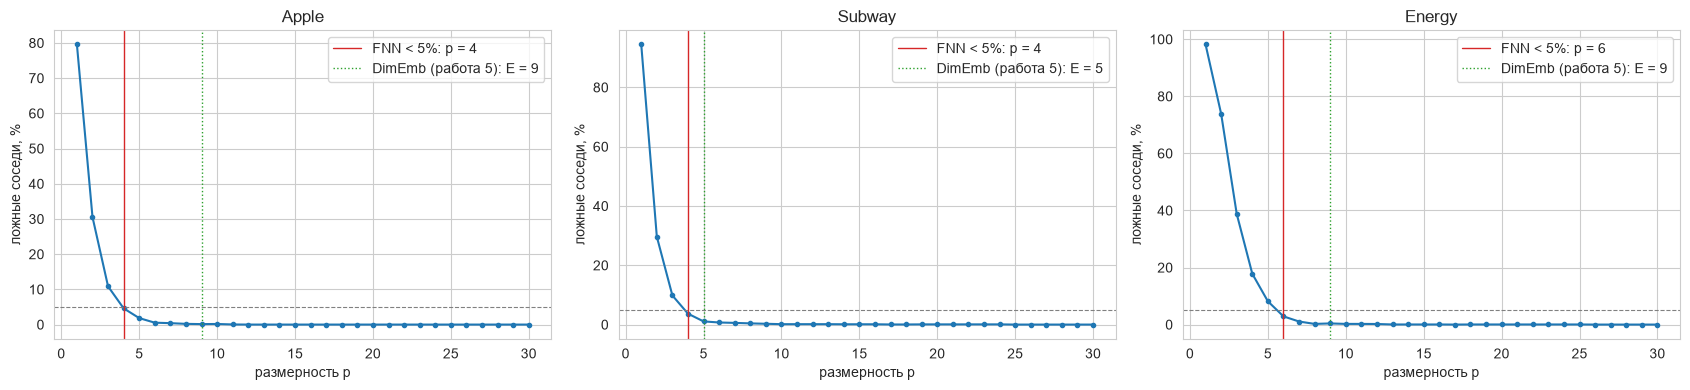

{'Apple': 4, 'Subway': 4, 'Energy': 6}

In [10]:
def fnn_fraction(x, dims, rtol=10.0, atol=2.0, theiler=10):
    x = (x - x.mean()) / x.std()
    res = []
    for d in dims:
        V = swv(x[:-1], d)                                   # У каждого вектора есть следующий отсчет x[i+d]
        nxt = x[d:d + len(V)]
        dist, idx = NearestNeighbors(n_neighbors=2 * theiler + 3).fit(V).kneighbors(V)
        rows = np.arange(len(V))
        ok = np.abs(idx - rows[:, None]) > theiler
        j = np.argmax(ok, axis=1)                            # Ближайший сосед вне окна Тейлера
        dj = np.maximum(dist[rows, j] / np.sqrt(d), 1e-12)   # Нормированная метрика
        gap = np.abs(nxt - nxt[idx[rows, j]])
        far = (gap / dj > rtol) | (np.sqrt((dj ** 2 * d + gap ** 2) / (d + 1)) > atol)
        res.append(far.mean())
    return np.array(res)


DIMS = np.arange(1, 31)
FNN, D_FNN = {}, {}
for name, x in FC_SERIES.items():
    FNN[name] = fnn_fraction(np.log(x[: ORIGINS[name][0]])[-3000:], DIMS)
    below = np.where(FNN[name] < 0.05)[0]
    D_FNN[name] = int(DIMS[below[0]] if len(below) else DIMS[FNN[name].argmin()])

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, name in zip(axes, FC_SERIES):
    ax.plot(DIMS, FNN[name] * 100, "o-", ms=3)
    ax.axhline(5, color="gray", ls="--", lw=0.8)
    ax.axvline(D_FNN[name], color="C3", lw=1, label=f"FNN < 5%: p = {D_FNN[name]}")
    ax.axvline(EMB[name], color="C2", lw=1, ls=":", label=f"DimEmb (работа 5): E = {EMB[name]}")
    ax.set(title=name, xlabel="размерность p", ylabel="ложные соседи, %")
    ax.legend()
plt.tight_layout(); plt.show()
D_FNN

* Доля ложных соседей падает ниже 5% при p=4 у Apple и метро и при p=6 у энергии. Это меньше, чем E из DimEmb (9, 5 и 9). Это из-за того, что критерии разные, FNN проверяет только, что у близких векторов близкий следующий отсчет, а DimEmb ждет насыщения корреляционной размерности. К тому же FNN считался по последним 3000 точкам, а DimEmb в работе 5 по 1000
* У Apple кривая FNN почти такая же, как у метро, хотя ряд неотличим от блуждания. Малая доля ложных соседей тут не говорит о низкоразмерной динамике: следующий отсчет почти равен последнему, поэтому продолжения близких векторов близки при любой p
* Строгого критерия выбора p нет, поэтому в локальной аппроксимации перебираем обе оценки вместе с 2E+1 и окном L из работы 4

## 1.2 Подбор параметров на валидации

Перебор: p ∈ {E из DimEmb, p по FNN, 2E+1, окно L из работы 4}, степень 0/1, итерационный/прямой прогноз, с центрированием и без. m = 3(p+1) по правилу из лекции

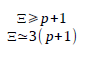



In [11]:
def la_fc(name, **cfg):
    x = FC_SERIES[name]
    return lambda o: np.exp(la_forecast(np.log(x[:o]), **cfg))


def grid_search(name, make_fc, grid, origins):
    rows = []
    for cfg in grid:
        E = run(name, make_fc(name, **cfg), origins)
        rows.append({**cfg, "h=1": np.median(E[:, 0]), "h=7": np.median(E[:, 1]), "h=14": np.median(E[:, 2]),
                     "score": score(E)})
    return pd.DataFrame(rows).sort_values("score").reset_index(drop=True)


LA_GRID, LA_BEST = {}, {}
for name in FC_SERIES:
    ps = sorted({EMB[name], D_FNN[name], 2 * EMB[name] + 1, LOOKBACK[name]})
    grid = [dict(p=p, order=o, mode=md_, center=c) for p in ps for o in (0, 1)
            for md_ in ("iter", "direct") for c in (False, True)]
    t0 = time.perf_counter()
    LA_GRID[name] = grid_search(name, la_fc, grid, VAL[name])
    LA_BEST[name] = LA_GRID[name].iloc[0][["p", "order", "mode", "center"]].to_dict()
    LA_BEST[name]["p"], LA_BEST[name]["order"] = int(LA_BEST[name]["p"]), int(LA_BEST[name]["order"])
    print(f"{name}: {len(grid)} конфигураций, {time.perf_counter() - t0:.1f} с; лучшая {LA_BEST[name]}")
    display(LA_GRID[name].head(5).style.format({k: "{:.2f}" for k in ["h=1", "h=7", "h=14", "score"]})
            .set_caption(f"{name}: топ-5 на валидации (медиана MAPE, %)"))

Apple: 32 конфигураций, 6.1 с; лучшая {'p': 9, 'order': 0, 'mode': 'iter', 'center': True}


,p,order,mode,center,h=1,h=7,h=14,score
0,9,0,iter,True,0.85,1.74,2.29,1.62
1,19,0,direct,True,0.85,2.08,2.17,1.70
2,20,0,iter,True,0.86,1.90,2.37,1.71
3,20,0,direct,True,0.86,1.97,2.34,1.72
4,19,0,iter,True,0.85,1.86,2.46,1.72


Subway: 32 конфигураций, 20.1 с; лучшая {'p': 11, 'order': 1, 'mode': 'iter', 'center': False}


,p,order,mode,center,h=1,h=7,h=14,score
0,11,1,iter,False,1.87,3.70,3.94,3.17
1,168,1,direct,True,2.54,3.21,4.02,3.26
2,11,1,direct,False,1.87,3.82,4.28,3.32
3,168,1,direct,False,2.04,4.15,4.70,3.63
4,168,1,iter,False,2.07,4.12,4.73,3.64


Energy: 32 конфигураций, 4.9 с; лучшая {'p': 56, 'order': 0, 'mode': 'direct', 'center': True}


,p,order,mode,center,h=1,h=7,h=14,score
0,56,0,direct,True,5.52,6.49,7.53,6.51
1,56,1,direct,True,3.69,8.87,8.99,7.18
2,19,0,iter,True,4.81,8.26,8.76,7.28
3,6,1,direct,False,5.05,8.38,8.43,7.29
4,56,1,iter,True,4.46,8.34,9.07,7.29


In [12]:
eff = []
for name, G in LA_GRID.items():
    for col in ["p", "order", "mode", "center"]:
        for v, s in G.groupby(col)["score"].min().items():
            eff.append(dict(series=name, параметр=col, значение=str(v), score=s))
eff = pd.DataFrame(eff).pivot_table(index=["параметр", "значение"], columns="series", values="score")
eff.style.format("{:.2f}").set_caption("Лучший score на валидации при фиксированном значении параметра (остальные перебираются)")

* **Apple** Лучшая конфигурация: p=9 (=E), нулевая степень, итерационный прогноз, центрирование, score 1.62. Весь топ-5 - нулевая степень с центрированием, а p от 9 до 20 и способ прогноза почти не влияют (1.62–1.72). Центрирование дает выигрыш (1.62 против 1.85): без него соседей ищут по уровню цены, а не по форме участка. Первая степень хуже (1.92), как и у энергии, на шумном ряде линейная модель подгоняет шум. p=4 из FNN тоже хуже (1.85)
  
* **Метро** Лучшая конфигурация: p=11 (=2E+1), первая степень, итерационный прогноз, без центрирования, score 3.17. Почти так же p=168 (неделя), прямой прогноз с центрированием, 3.26. Нулевая степень заметно хуже (4.24), здесь среднее по соседям сглаживает пик в час пик, а линейная модель подстраивает его под текущее состояние. p из FNN (4) и E (5) хуже: 5.24 и 4.67, окна в 4-5 ч хуже различают похожие участки суток (например, подъем утром и вечером)

* **Энергия** Лучшая конфигурация: p=56, нулевая степень, прямой прогноз, центрирование, score 6.51. Первая степень хуже (7.18): ряд шумный, и линейная модель по m = 3(p+1) соседям подгоняет шум. p=6 (FNN) и 9 (E) хуже: 7.29 и 7.75

* **Степень модели** Первая степень выигрывает только на гладком периодическом ряде (метро). На шумных рядах (энергия, Apple) лучше нулевая, там прогноз по среднему образов соседей устойчивее

* **Итерационный или прямой** На шумной энергии прямой лучше (6.51 против 7.28), потому что ошибка не накапливается. На метро итерационный немного лучше (3.17 против 3.26), у Apple тоже (1.62 против 1.70), но разница мала

* **Размерность вложения** Оценка p по FNN хуже лучшего варианта на всех рядах, а у Apple и метро хуже всех остальных p (у энергии p=6 из FNN лучше, чем E=9: 7.29 против 7.75). Лучшие p больше оценок FNN: E у Apple, 2E+1 у метро, окно L = 56 из работы 4 у энергии

## 1.3 Как выглядит прогноз ЛА

Последний тестовый блок, лучшая конфигурация. Серым - это найденные соседи текущего состояния и их продолжения (для прямого прогноза; при центрировании они совмещены по последней точке), черным - текущее состояние и факт, красным - прогноз

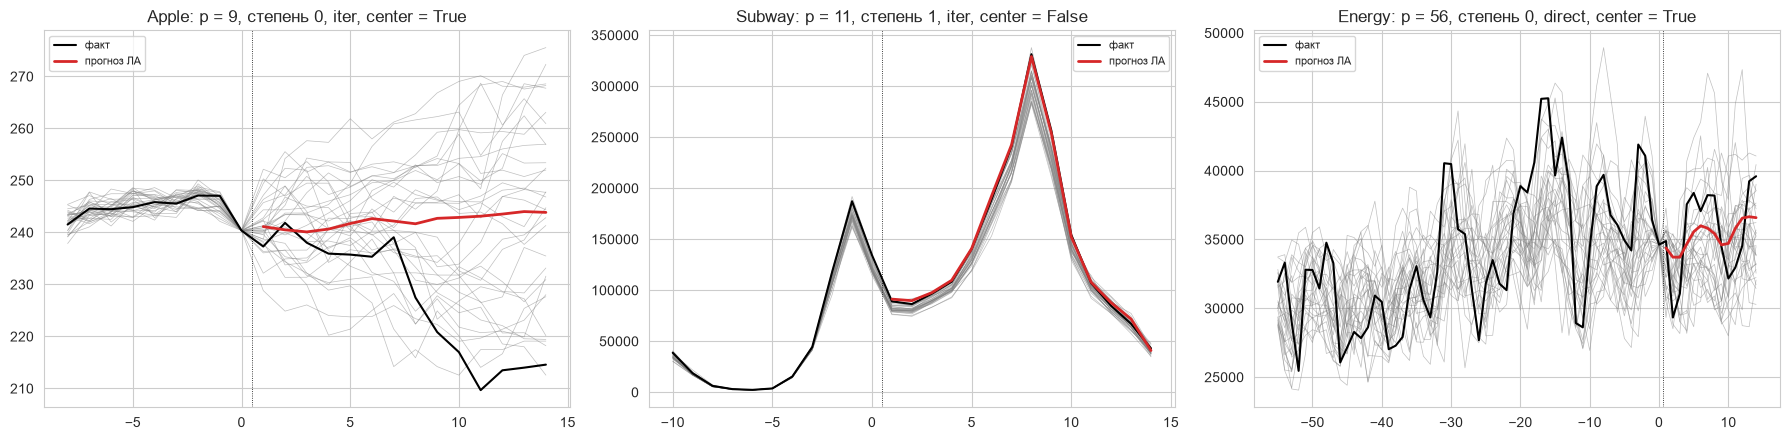

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
for ax, name in zip(axes, FC_SERIES):
    x, o, c = FC_SERIES[name], ORIGINS[name][-1], LA_BEST[name]
    z, p = np.log(x[:o]), c["p"]
    V, Y = delay_pairs(z, p, H_MAX)
    fc_, nb = local_predict(V, Y, z[-p:], 3 * (p + 1), c["order"], c["center"])
    show = nb[np.argsort(((V[nb] - z[-p:]) ** 2).sum(1))][:30]
    tt = np.arange(-p + 1, H_MAX + 1)
    for s in show:
        seg = np.r_[V[s], Y[s]]
        if c["center"]:
            seg = seg - V[s, -1] + z[-1]
        ax.plot(tt, np.exp(seg), color="gray", lw=0.5, alpha=0.5)
    ax.plot(tt, x[o - p:o + H_MAX], color="k", lw=1.5, label="факт")
    ax.plot(np.arange(1, H_MAX + 1), np.exp(la_forecast(z, **c)),
            color="C3", lw=2, label="прогноз ЛА")
    ax.axvline(0.5, color="k", lw=0.6, ls=":")
    ax.set_title(f"{name}: p = {p}, степень {c['order']}, {c['mode']}, center = {c['center']}")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

* **Apple** Соседи хорошо совпадают с текущим состоянием (последние 9 дней), но их продолжения расходятся веером вверх и вниз примерно симметрично. Среднее по ним почти горизонтально, так что прогноз близок к naive (последнему значению) и падения цены не видит. Это поведение случайного блуждания
  
* **Метро** Продолжения соседей идут плотным пучком и повторяют форму суток, включая пик через 8 часов. Прогноз схож с фактом. Траектория детерминированная, близкие состояния в прошлом имеют близкие продолжения, и это именно тот случай, на который рассчитан метод

* **Энергия** Разброс продолжений соседей большой, сопоставим с размахом самого ряда (примерно 28-45 тыс. МВт). Нулевая степень усредняет их в гладкую кривую: общий уровень и направление прогноз ловит, а дневные скачки (погоду) нет

* Ширина пучка продолжений показывает, насколько ряд предсказуем методом аналогов - узкий пучок у метро, широкий у энергии, расходящийся веер у Apple

# 2. Метод максимального подобия (И.А. Чучуева)

1. Базовая выборка - последние M значений ряда Z^M_{T−M+1}
2. Перебором по всем k ищется выборка Z^M_k той же длины с максимальным |ρ| (коэффициент Пирсона) с базовой. Рассматриваются только k, после которых известно P=14 значений
3. МНК: Z^M_{T−M+1} = α1·Z^M_kmax + α0
4. Прогноз сразу на P шагов: α1·(P значений после Z^M_kmax) + α0

Метод работает на исходном (не логарифмированном) ряду, уровень учитывают α1 и α0. Единственный параметр - M, подбираем на валидации

Дополнительно сделала усреднение прогнозов по K = 5 лучшим непересекающимся выборкам. Обоснование - одна выборка дает шумный прогноз

Apple: 3.2 с; лучшая {'M': 10, 'K': 5}
Subway: 3.3 с; лучшая {'M': 24, 'K': 5}
Energy: 3.6 с; лучшая {'M': 730, 'K': 5}


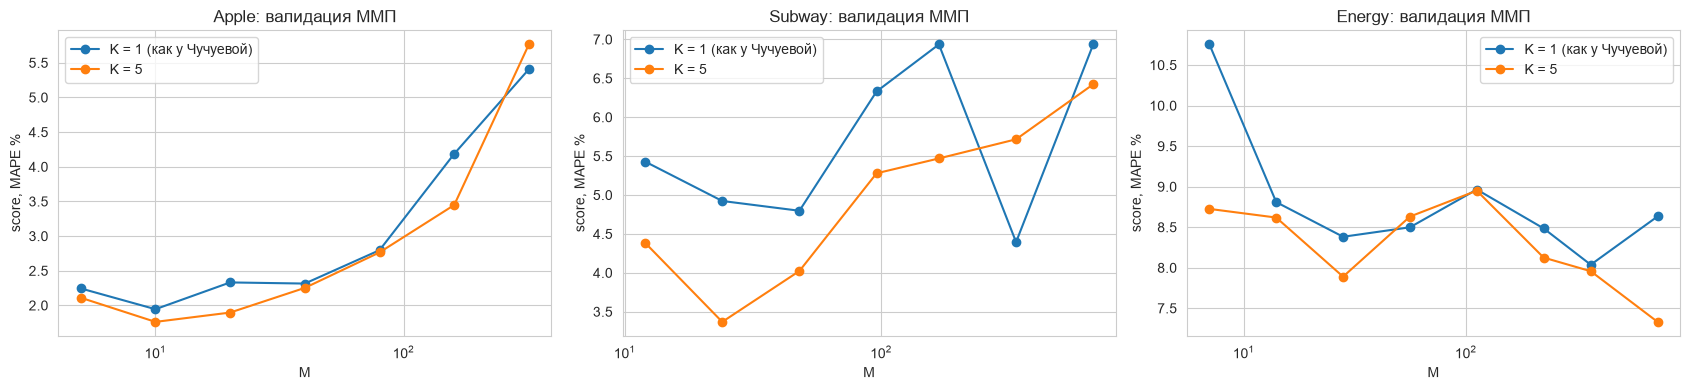

In [14]:
def mmp_forecast(x, M, P=H_MAX, K=1):
    n = len(x)
    W = swv(x[: n - P], M)
    b = x[n - M:]
    Wc, bc = W - W.mean(1, keepdims=True), b - b.mean()
    rho = np.abs(Wc @ bc) / (np.linalg.norm(Wc, axis=1) * np.linalg.norm(bc) + 1e-12)
    chosen = []
    for k in np.argsort(rho)[::-1]:                          # K лучших непересекающихся выборок
        if all(abs(k - c) >= M for c in chosen):
            chosen.append(k)
        if len(chosen) == K:
            break
    fc = []
    for k in chosen:
        (a1, a0), *_ = np.linalg.lstsq(np.c_[x[k:k + M], np.ones(M)], b, rcond=None)
        fc.append(a1 * x[k + M:k + M + P] + a0)
    return np.mean(fc, 0), chosen, rho


def mmp_fc(name, M, K=1):
    x = FC_SERIES[name]
    return lambda o: mmp_forecast(x[:o], M, K=K)[0]


M_GRID = {"Apple": [5, 10, 20, 40, 80, 160, 320],
          "Subway": [12, 24, 48, 96, 168, 336, 672],
          "Energy": [7, 14, 28, 56, 112, 224, 365, 730]}
MMP_GRID, MMP_BEST = {}, {}
for name in FC_SERIES:
    t0 = time.perf_counter()
    MMP_GRID[name] = grid_search(name, mmp_fc, [dict(M=M, K=K) for M in M_GRID[name] for K in (1, 5)], VAL[name])
    MMP_BEST[name] = {k: int(v) for k, v in MMP_GRID[name].iloc[0][["M", "K"]].items()}
    print(f"{name}: {time.perf_counter() - t0:.1f} с; лучшая {MMP_BEST[name]}")

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, name in zip(axes, FC_SERIES):
    G = MMP_GRID[name]
    for K, gk in G.groupby("K"):
        gk = gk.sort_values("M")
        ax.plot(gk["M"], gk["score"], "o-", label=f"K = {K}" + (" (как у Чучуевой)" if K == 1 else ""))
    ax.set(xscale="log", title=f"{name}: валидация ММП", xlabel="M", ylabel="score, MAPE %")
    ax.legend()
plt.tight_layout(); plt.show()

* **K = 5 или K = 1.** Усреднение по 5 выборкам в большинстве точек сетки лучше одиночной выборки максимального подобия. Исключения: самые длинные M у Apple (320) и метро (336), у энергии при M = 56-112 разницы почти нет. Одна выборка - это одна реализация шума, поэтому кривая для K = 1 скачет (у метро 4.4-6.9 без явной зависимости от M), и выбор M по ней нестабилен

* **Apple** Лучшее M=10, K=5, score 1.77, это немного хуже ЛА (1.62). С ростом M ошибка быстро растет: при M ≥ 80 больше 2.8, при M = 320 около 5.4-5.8. Длинный участок блуждания не повторяется, и самая похожая выборка находится только за счет общего тренда, а ее продолжение не связано с будущим

* **Метро** Лучшее M=24 (сутки), K=5, score 3.37. Суточный профиль повторяется почти точно, и похожих участков много. С ростом M score при K=5 растет: длинная выборка захватывает переход между буднями и выходными, и подходящих аналогов становится меньше

* **Энергия** Минимум на краю сетки, M=730 (2 года): 7.33 против 7.9-9.0 при M ≤ 365. Пики |ρ| повторяются с периодом около года, так что при длинной базовой выборке ММП фактически становится сезонным прогнозом «как в тот же сезон несколько лет назад» с линейной поправкой. Даже лучший вариант хуже ЛА (6.51)

Иллюстрация на последнем тестовом блоке с K=1 и лучшим M: |ρ(k)| по всей истории, найденная выборка после линейного преобразования α1·Z + α0 и ее продолжение

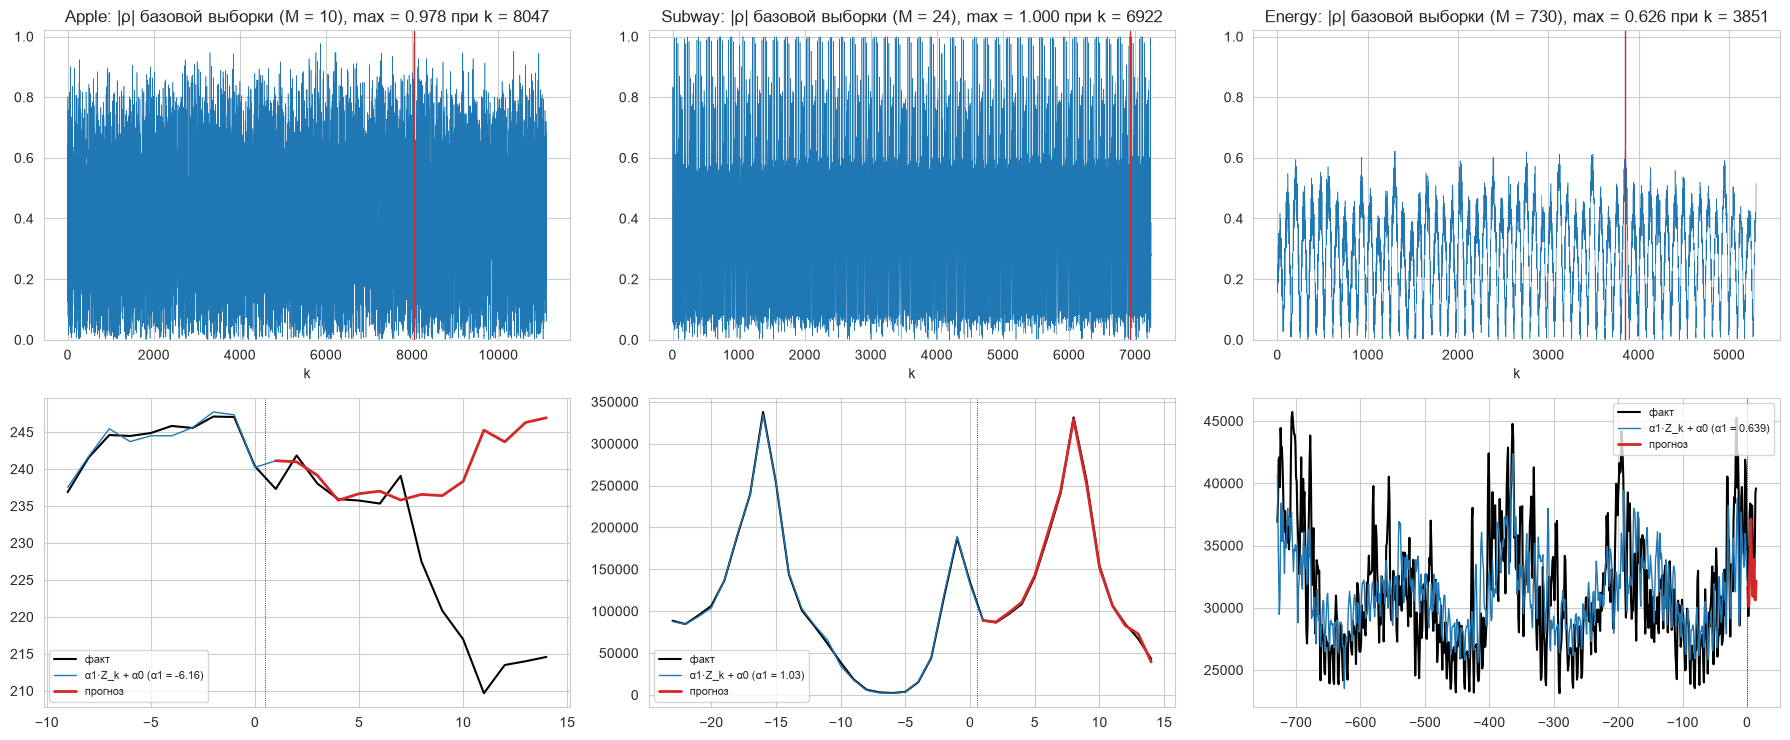

In [15]:
fig, axes = plt.subplots(2, 3, figsize=(18, 7.5))
for j, name in enumerate(FC_SERIES):
    x, o, M = FC_SERIES[name], ORIGINS[name][-1], MMP_BEST[name]["M"]
    fc_, (k,), rho = mmp_forecast(x[:o], M, K=1)
    ax = axes[0, j]
    ax.plot(rho, lw=0.4); ax.axvline(k, color="C3", lw=1)
    ax.set(title=f"{name}: |ρ| базовой выборки (M = {M}), max = {rho[k]:.3f} при k = {k}", xlabel="k", ylim=(0, 1.02))
    (a1, a0), *_ = np.linalg.lstsq(np.c_[x[k:k + M], np.ones(M)], x[o - M:o], rcond=None)
    ax = axes[1, j]
    tt = np.arange(-M + 1, H_MAX + 1)
    ax.plot(tt, x[o - M:o + H_MAX], "k", lw=1.5, label="факт")
    ax.plot(tt, a1 * x[k:k + M + H_MAX] + a0, color="C0", lw=1, label=f"α1·Z_k + α0 (α1 = {a1:.3g})")
    ax.plot(np.arange(1, H_MAX + 1), fc_, color="C3", lw=2, label="прогноз")
    ax.axvline(0.5, color="k", lw=0.6, ls=":"); ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

* **Apple** max |ρ| = 0.978, но при M=10 высокие корреляции встречаются по всей истории (облако |ρ| доходит до 0.9 при любом k), так что максимальное подобие здесь в основном случайное. α1 = −6.18: найденная выборка антикоррелирует с базовой (метод берет |ρ|, знак не важен), и после МНК ее продолжение переворачивается и растягивается в 6 раз. Прогноз уходит вверх, а цена падает с 240 до 210. Это и есть прогнозировать можно, но осторожно, так как на блуждании коэффициенты подобия ничем не ограничены и могут разгонять прогноз
  
* **Метро** |ρ| = 1.000, α1 = 1.03: найден тот же день недели ровно 2 недели назад (k = o − 336), то есть почти точная копия базовой выборки без масштабирования. На графике |ρ| видны регулярные пики около 1 с суточным периодом, и хороших аналогов много. Прогноз совпадает с фактом, включая вечерний пик. Для детерминированного цикла метод работает как надо

* **Энергия** Пики |ρ| повторяются с периодом около года, максимум 0.626 найден примерно 4 года назад (k = 3851, сдвиг около 1460 сут). Подобие слабое, и МНК уменьшает амплитуду найденной выборки (α1 = 0.64 < 1). Годовой ход выборка повторяет, а дневные колебания (погода) нет

* Модуль |ρ| показывает, насколько ряду подходит метод: у метро много аналогов с |ρ| примерно 1, у энергии лучший аналог дает лишь 0.63, у Apple высокие |ρ| получаются случайно и ничего не гарантируют

# 3. SSA (сингулярный спектральный анализ)


1. Траекторная матрица X (L×K, K = N-L+1) из лог-ряда
2. Собственные числа и векторы S = XXᵀ, элементарные матрицы X_i = U_i U_iᵀX
3. Диагональное усреднение X_i → элементарные компоненты ряда; выбор группировки по спектру собственных чисел, матрице w-корреляций и парным диаграммам собственных векторов
4. Прогноз по линейной рекуррентной формуле (рекуррентный SSA-прогноз): по первым r собственным векторам U_r, π - последняя строка U_r, ν² = Σπ²

   x_{N+1} = Rᵀ(x_{N−L+2}, …, x_N), R = U_r^∇π / (1 − ν²), U_r^∇ - U_r без последней строки

   Рекуррентная формула применяется к восстановленному по r компонентам ряду, новые точки считаются последовательно

Разложение берется не по всей истории, а по последним N_hist точкам: N_hist, L и r подбираются на валидации

In [16]:
def ssa_decompose(z, L):
    X = swv(np.asarray(z, float), L).T                     # L×K, X[a, b] = z[a+b] (матрица Ганкеля)
    lam, U = np.linalg.eigh(X @ X.T)
    o = np.argsort(lam)[::-1]
    return X, np.clip(lam[o], 0, None), U[:, o]


def ssa_components(X, U, r):
    """Элементарные компоненты 1..r: диагональное усреднение U_i (U_i^T X) через свертку"""
    L, K = X.shape
    cnt = np.convolve(np.ones(L), np.ones(K))
    W = X.T @ U[:, :r]
    return np.stack([np.convolve(U[:, i], W[:, i]) / cnt for i in range(r)])


def ssa_rforecast(y, U, r, H=H_MAX):
    """y - восстановленный ряд, U - собственные векторы"""
    Ur = U[:, :r]
    pi = Ur[-1]
    R = Ur[:-1] @ pi / (1 - pi @ pi)
    L = Ur.shape[0]
    y = list(y)
    for _ in range(H):
        y.append(R @ np.array(y[-(L - 1):]))
    return np.array(y[-H:])


def wcorr(F, L):
    N = F.shape[1]; K = N - L + 1
    w = np.minimum(np.minimum(np.arange(1, N + 1), min(L, K)), N - np.arange(N))
    G = (F * w) @ F.T
    d = np.sqrt(np.diag(G))
    return np.abs(G / np.outer(d, d))

## 3.1 Разложение рядов

Для иллюстрации - последние N_hist точек перед тестом: Apple L = 250 (торговый год), N_hist = 2000; метро L = 168 (неделя), N_hist = 26 недель; энергия L = 365, N_hist = 8 лет

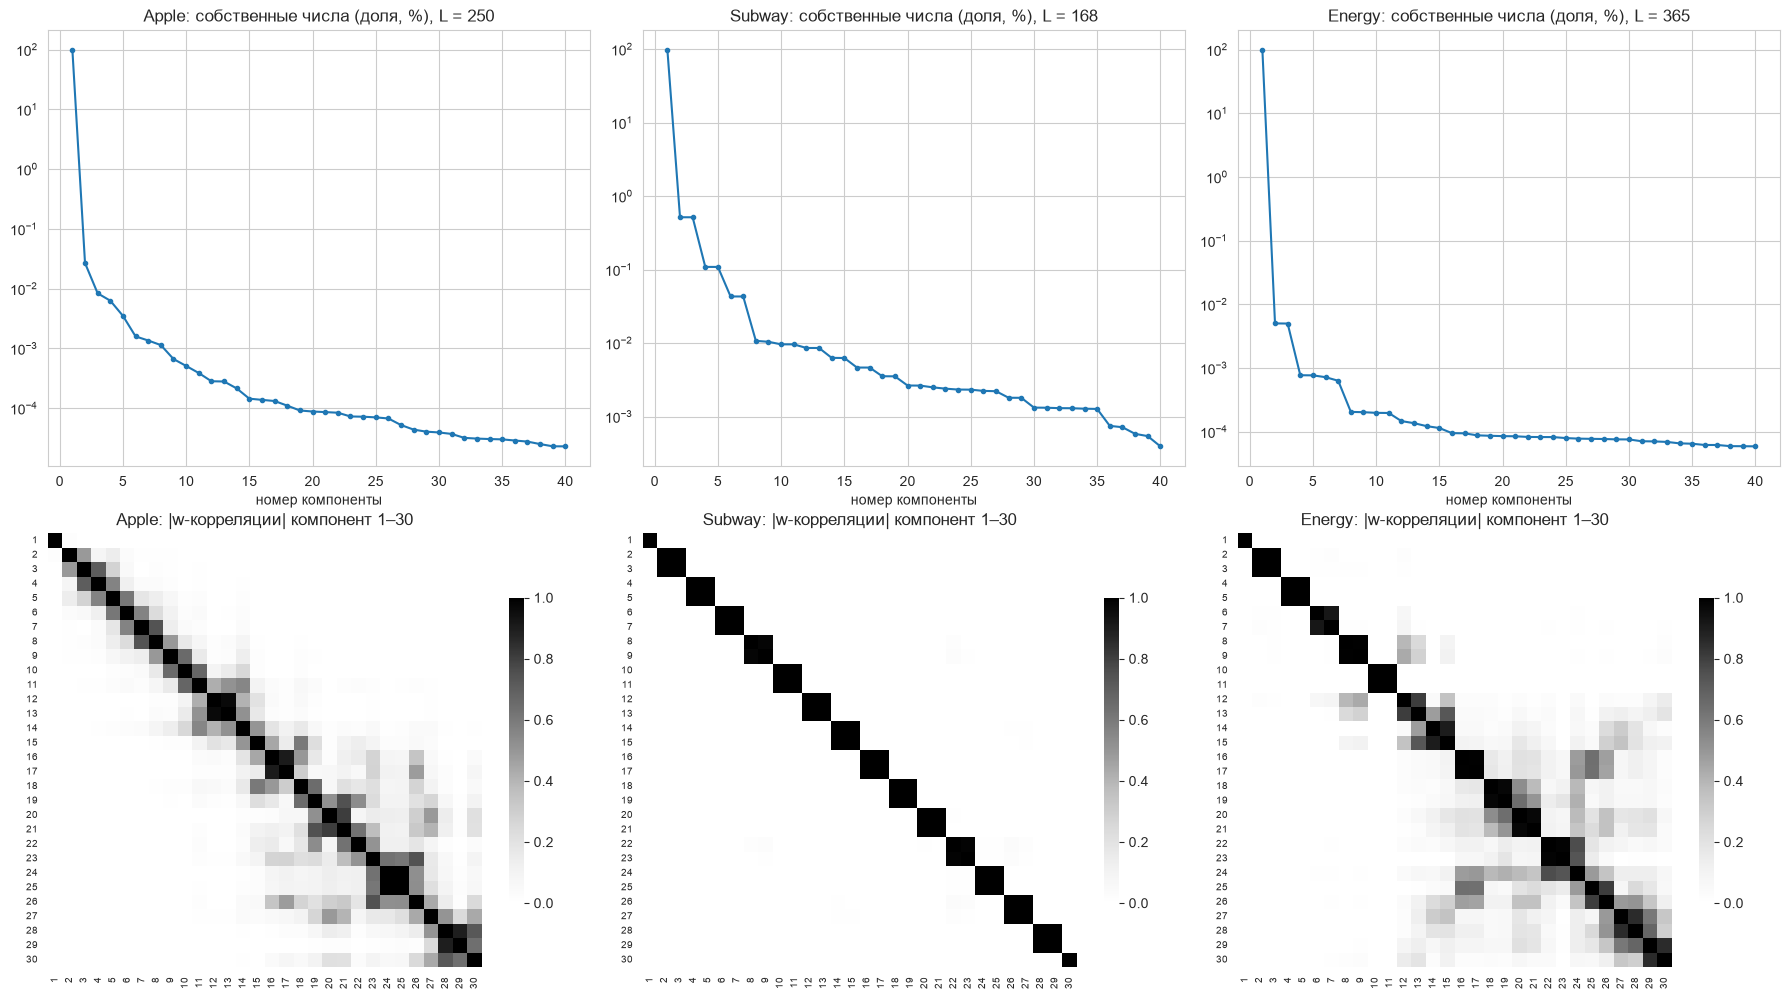

In [17]:
DEMO = {"Apple": (250, 2000), "Subway": (168, 168 * 26), "Energy": (365, 365 * 8)}
DEC = {}
for name, (L, nh) in DEMO.items():
    z = np.log(FC_SERIES[name][: ORIGINS[name][0]])[-nh:]
    X, lam, U = ssa_decompose(z, L)
    DEC[name] = dict(z=z, L=L, lam=lam, U=U, F=ssa_components(X, U, 30))

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for j, (name, d) in enumerate(DEC.items()):
    share = d["lam"] / d["lam"].sum() * 100
    ax = axes[0, j]
    ax.semilogy(np.arange(1, 41), share[:40], "o-", ms=3)
    ax.set(title=f"{name}: собственные числа (доля, %), L = {d['L']}", xlabel="номер компоненты")
    ax = axes[1, j]
    sns.heatmap(wcorr(d["F"], d["L"]), ax=ax, cmap="Greys", vmin=0, vmax=1, square=True,
                xticklabels=range(1, 31), yticklabels=range(1, 31), cbar_kws={"shrink": 0.7})
    ax.tick_params(labelsize=7)
    ax.set_title(f"{name}: |w-корреляции| компонент 1–30")
plt.tight_layout(); plt.show()

* Ряд не центрирован, поэтому первая компонента (уровень лог-ряда) забирает больше 99% энергии. Структура ряда видна по следующим компонентам
  
* **Apple** Ступеней из равных пар нет, спектр плавно убывает. На w-корреляциях соседние компоненты коррелируют между собой вдоль всей диагонали, а отдельные блоки (12–13, 24–25, 28–30) не отделены от окружения. Это не гармоники, а медленные колебания тренда, размазанные по многим компонентам

* **Метро** После первой компоненты спектр идет ступенями из пар почти равных собственных чисел: 2-3 (около 0.5%), 4-5 (около 0.1%), 6-7 (около 0.04%), дальше пары меньше. Равные пары - признак гармоник (синус и косинус одной частоты). Матрица w-корреляций блочно-диагональная из блоков 2×2 вплоть до 30-й компоненты: пары хорошо отделены друг от друга, то есть периодическая структура чистая

* **Энергия** Выделяются пара 2-3 и две некие полки по 4 почти равных собственных числа (4-7 и 8-11), на w-корреляциях это пять отдельных блоков 2×2 (2–3, 4–5, 6–7, 8–9, 10–11). Начиная примерно с 12-й компоненты спектр плоский, а w-корреляции перемешаны (компоненты 12–30 коррелируют между собой) - это шум. Детерминированной структуры немного: несколько гармоник поверх сильного шума

* Спектр и w-корреляции разделяют ряды так же, как фазовый анализ в работе 5: у метро чистый цикл, у энергии цикл плюс шум, у Apple периодики нет

Парные диаграммы соседних собственных векторов

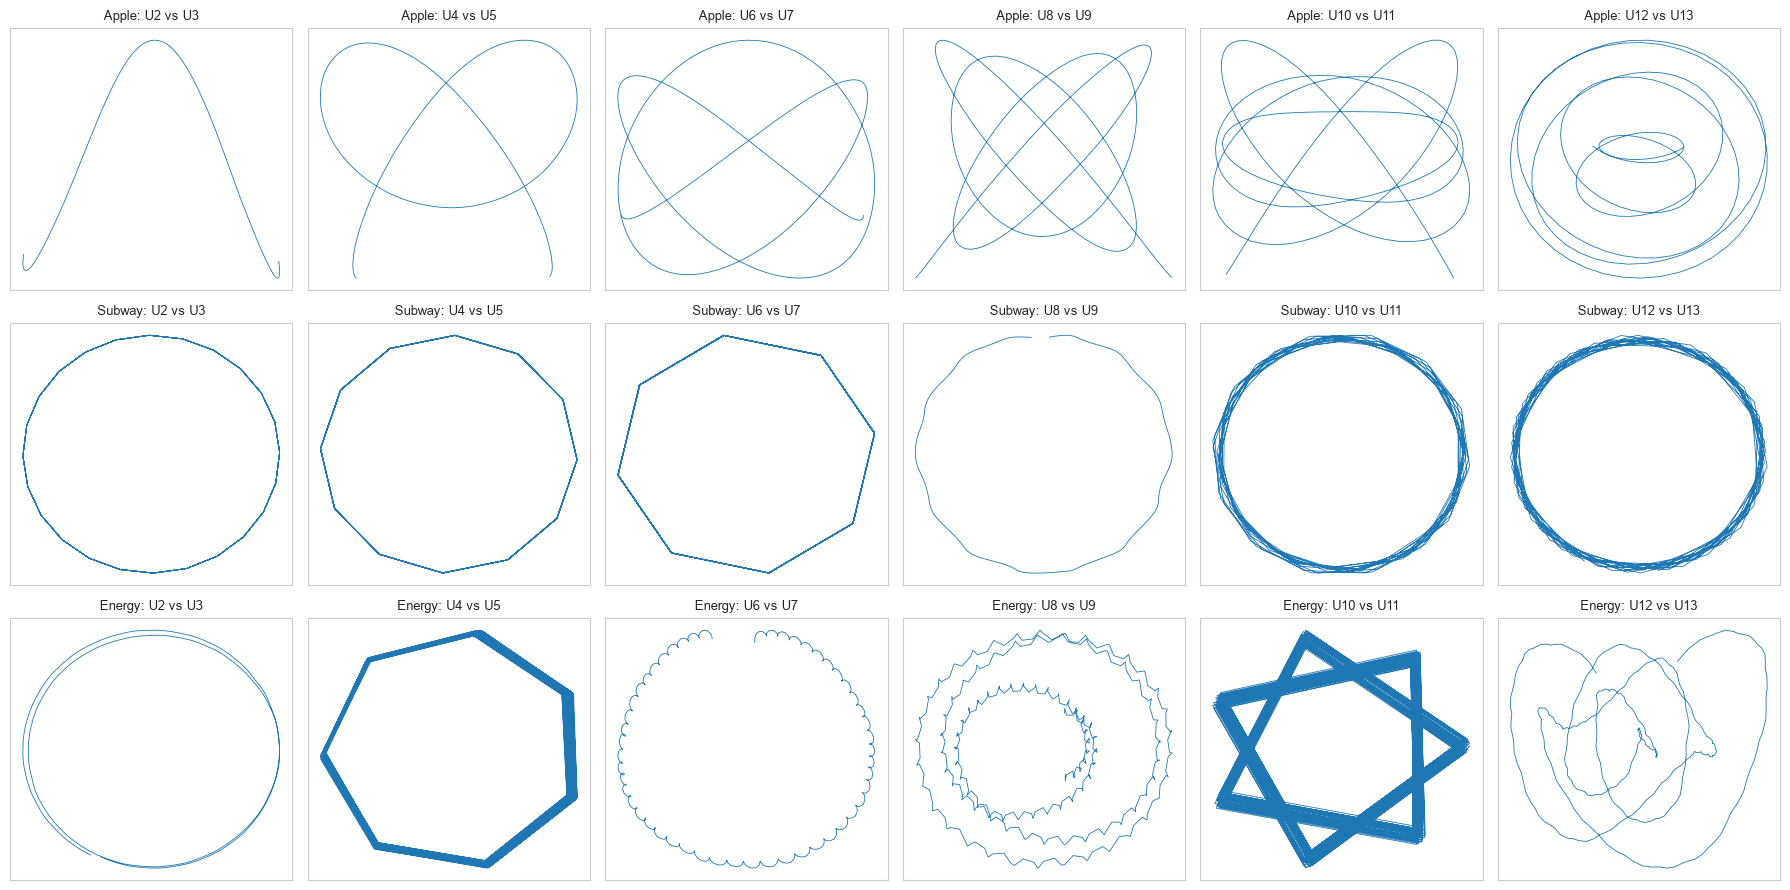

In [18]:
fig, axes = plt.subplots(3, 6, figsize=(18, 9))
for i, (name, d) in enumerate(DEC.items()):
    U = d["U"]
    for j in range(6):
        ax = axes[i, j]
        a, b = 2 * j + 1, 2 * j + 2
        ax.plot(U[:, a], U[:, b], lw=0.6)
        ax.set_title(f"{name}: U{a + 1} vs U{b + 1}", fontsize=9)
        ax.set_xticks([]); ax.set_yticks([])
plt.tight_layout(); plt.show()

* **Apple** - фигуры красивые, но обманчивые. U2–U3 - арка (полволны за окно, медленный тренд), дальше петли и фигуры из синусоид разной частоты. Частоты в паре разные, и фигура не замыкается в окружность. Гладкость кривых - свойство метода, а не периодика в данных
  
* **Метро** - U2–U3 - правильный 24-угольник (суточный период, одна вершина на каждый час), U4–U5 - 12-угольник (12 ч), U6–U7 - 8-угольник (8 ч), то есть суточный цикл и его гармоники. Дальше (U8–U13) идут окружности с дрожанием, то есть те же суточные гармоники, промодулированные недельным циклом

* **Энергия** - U2–U3 - почти окружность, один оборот за окно L=365 (годовой цикл). U4–U5 - семиугольник (неделя). U10–U11 - семиконечная звезда {7/2}, вторая гармоника недели с периодом 3.5 сут. U6–U7 - окружность с зубами, около 52 на оборот (годовой цикл с недельной рябью), U8–U9 - такая же зубчатая спираль. U12–U13 - уже каракули, то есть шум

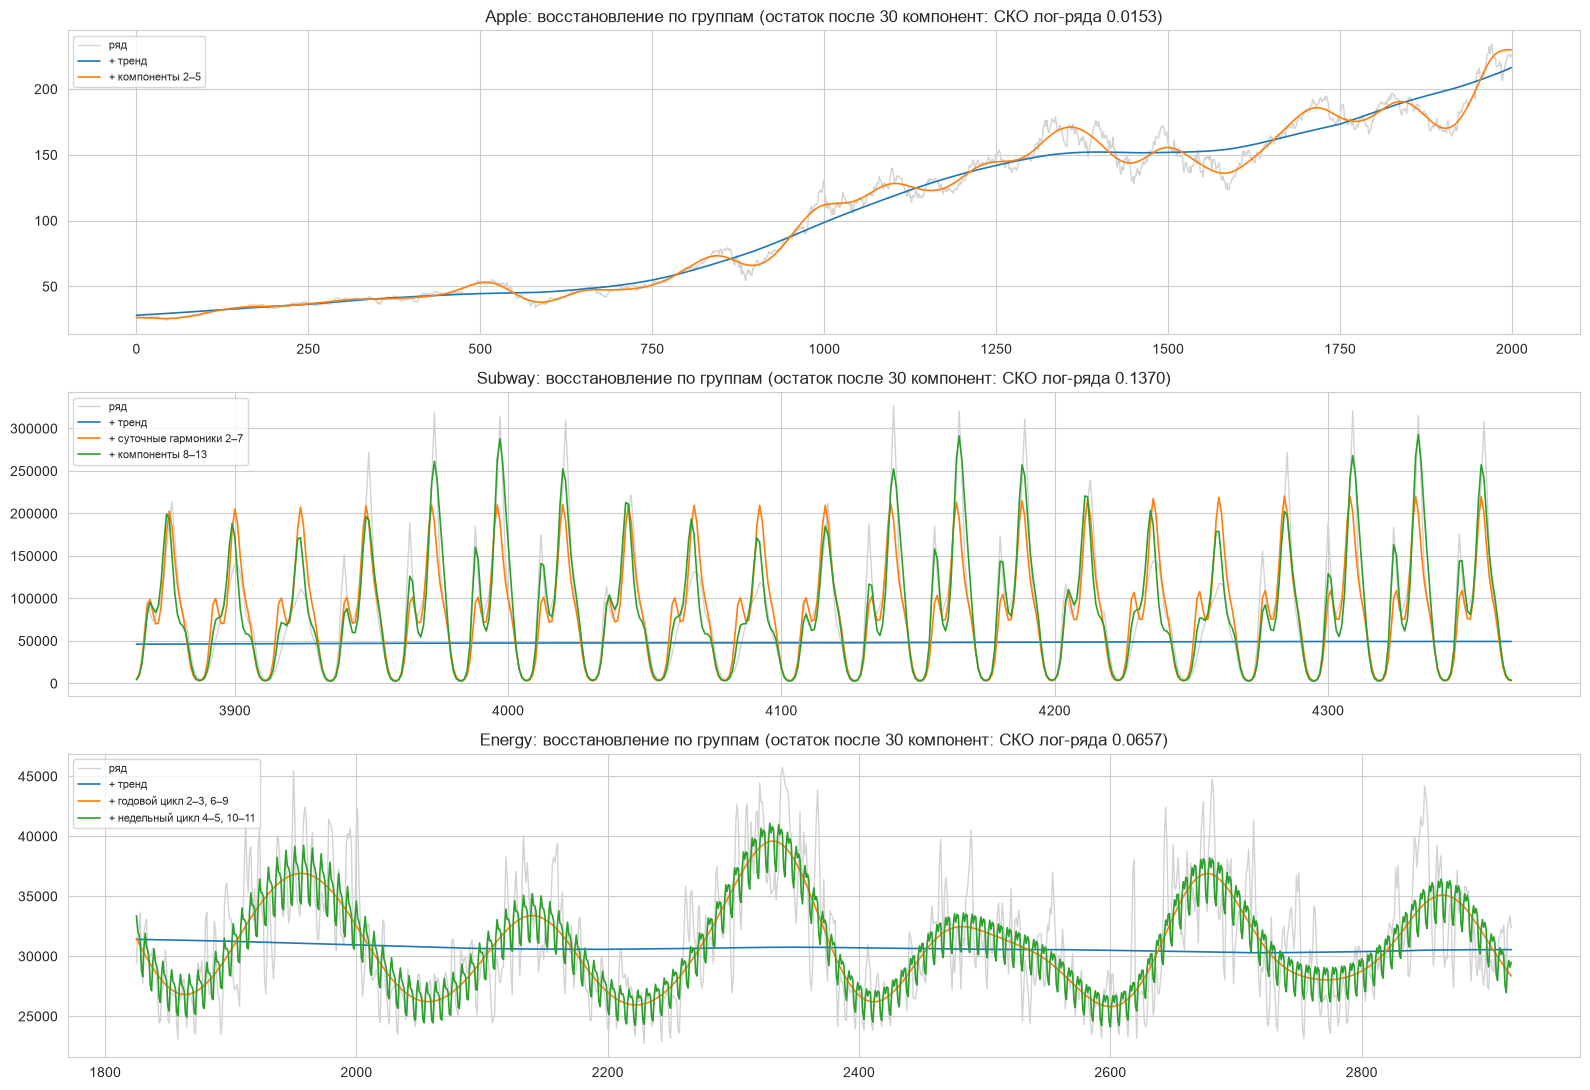

In [19]:
GROUPS = {"Apple": {"тренд": [0], "компоненты 2–5": [1, 2, 3, 4]},
          "Subway": {"тренд": [0], "суточные гармоники 2–7": list(range(1, 7)), "компоненты 8–13": list(range(7, 13))},
          "Energy": {"тренд": [0], "годовой цикл 2–3, 6–9": [1, 2, 5, 6, 7, 8], "недельный цикл 4–5, 10–11": [3, 4, 9, 10]}}
fig, axes = plt.subplots(3, 1, figsize=(16, 11))
for ax, (name, d) in zip(axes, DEC.items()):
    z, F = d["z"], d["F"]
    tail = slice(-min(len(z), {"Apple": 2000, "Subway": 168 * 3, "Energy": 365 * 3}[name]), None)
    t = np.arange(len(z))[tail]
    ax.plot(t, np.exp(z[tail]), color="lightgray", lw=1, label="ряд")
    rec = 0
    for g, idx in GROUPS[name].items():
        rec = rec + F[idx].sum(0)
        ax.plot(t, np.exp(rec[tail]), lw=1.2, label=f"+ {g}")
    resid = z - F[:30].sum(0)
    ax.set_title(f"{name}: восстановление по группам (остаток после 30 компонент: СКО лог-ряда {resid.std():.4f})")
    ax.legend(fontsize=8)
plt.tight_layout(); plt.show()

* **Apple** Первая компонента - гладкий S-образный тренд (рост с 28 до 220 за 2000 торговых дней), компоненты 2-5 добавляют медленные колебания вокруг него длительностью в сотни дней. Остаток (СКО лог-ряда 0.015, то есть около 1.5 %) - дневной шум, колебания не повторяются с постоянным периодом. В конце окна тренд отстает от ряда (около 215 против 230), поэтому продление тренда при прогнозе дает систематический сдвиг уровня
* **Метро** Тренд - почти постоянный уровень (около 50 тыс.). Суточные гармоники 2-7 дают одинаковый для всех дней суточный профиль с двумя пиками (утро и вечер), но пики одной высоты. Компоненты 8-13 добавляют недельную модуляцию: высокие пики в будни, низкие в выходные, и только с ними восстановление повторяет вечерние пики около 300 тыс. Остаток после 30 компонент заметный (СКО лог-ряда 0.137): ночные минимумы почти нулевые, и в логарифме небольшие отклонения ночью дают большие относительные ошибки
* **Энергия** Тренд почти постоянный. Годовая группа дает два пика в год, зимний (отопление) и летний (кондиционирование), причем летний выше. Недельная группа дает рябь с периодом 7 суток (будни и выходные). Остаток после 30 компонент (СКО лог-ряда 0.066) - погодный шум

## 3.2 Подбор L, N_hist и r на валидации

Apple: 44 конфигураций, 1.0 с; лучшая {'L': 20, 'hist': 2000, 'r': 10}


,L,hist,r,h=1,h=7,h=14,score
0,20,2000,10,1.11,1.76,2.40,1.76
1,20,500,10,0.97,1.83,2.61,1.80
2,20,2000,3,1.21,2.08,2.18,1.82
3,20,500,3,1.09,2.30,2.36,1.92
4,60,2000,10,1.27,2.18,2.58,2.01


Subway: 58 конфигураций, 4.0 с; лучшая {'L': 168, 'hist': 4368, 'r': 80}


,L,hist,r,h=1,h=7,h=14,score
0,168,4368,80,2.27,5.24,5.52,4.34
1,336,4368,120,4.34,4.68,5.10,4.71
2,336,1344,120,4.18,5.17,5.51,4.95
3,336,1344,150,5.46,4.63,4.94,5.01
4,336,1344,100,4.74,5.59,5.46,5.26


Energy: 46 конфигураций, 2.9 с; лучшая {'L': 182, 'hist': 2920, 'r': 40}


,L,hist,r,h=1,h=7,h=14,score
0,182,2920,40,3.63,8.59,8.46,6.90
1,182,2920,60,4.36,8.01,8.46,6.94
2,182,1095,30,4.13,7.42,9.73,7.09
3,56,2920,40,5.23,8.47,8.00,7.24
4,182,2920,30,4.70,8.52,8.83,7.35


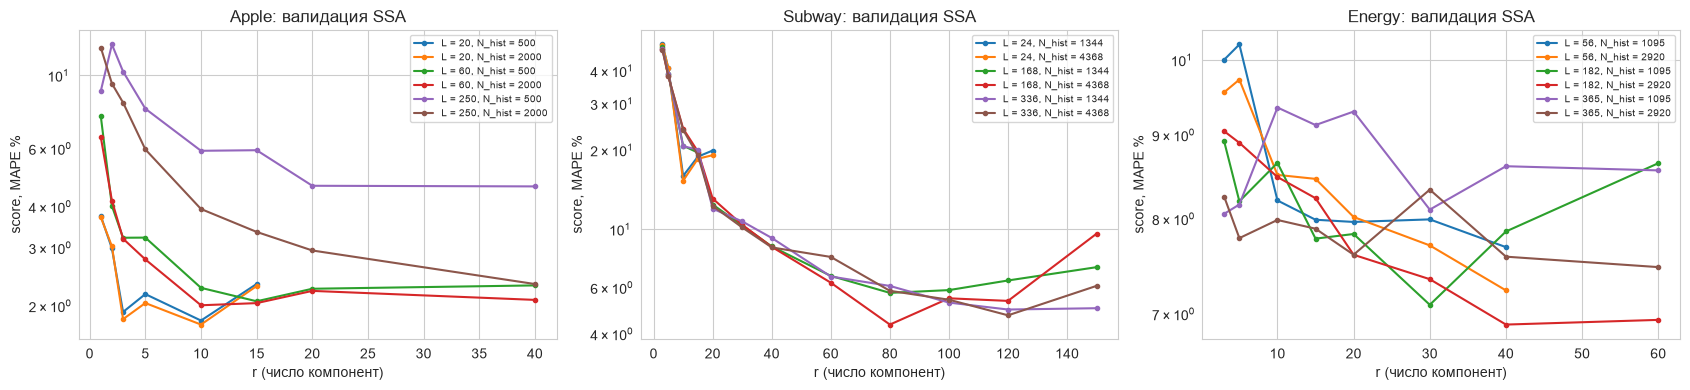

In [20]:
SSA_SPACE = {"Apple": dict(L=[20, 60, 250], hist=[500, 2000], r=[1, 2, 3, 5, 10, 15, 20, 40]),
             "Subway": dict(L=[24, 168, 336], hist=[168 * 8, 168 * 26], r=[3, 5, 10, 15, 20, 30, 40, 60, 80, 100, 120, 150]),
             "Energy": dict(L=[56, 182, 365], hist=[365 * 3, 365 * 8], r=[3, 5, 10, 15, 20, 30, 40, 60])}


def ssa_eval(name, origins, L, nh, rs):
    """MAPE для всех r сразу: разложение одно на блок"""
    x = FC_SERIES[name]
    out = {r: [] for r in rs}
    for o in origins:
        z = np.log(x[max(0, o - nh):o])
        X, lam, U = ssa_decompose(z, L)
        F = ssa_components(X, U, max(rs))
        for r in rs:
            f = np.exp(ssa_rforecast(F[:r].sum(0), U, r))
            out[r].append([mape(x[o:o + h], f[:h]) for h in HORIZONS])
    return {r: np.array(v) for r, v in out.items()}


SSA_GRID, SSA_BEST = {}, {}
for name, sp in SSA_SPACE.items():
    t0, rows = time.perf_counter(), []
    for L in sp["L"]:
        for nh in sp["hist"]:
            rs = [r for r in sp["r"] if r < L]
            for r, E in ssa_eval(name, VAL[name], L, nh, rs).items():
                rows.append(dict(L=L, hist=nh, r=r, **{f"h={h}": np.median(E[:, i]) for i, h in enumerate(HORIZONS)},
                                 score=score(E)))
    SSA_GRID[name] = pd.DataFrame(rows).sort_values("score").reset_index(drop=True)
    SSA_BEST[name] = {k: int(v) for k, v in SSA_GRID[name].iloc[0][["L", "hist", "r"]].items()}
    print(f"{name}: {len(rows)} конфигураций, {time.perf_counter() - t0:.1f} с; лучшая {SSA_BEST[name]}")
    display(SSA_GRID[name].head(5).style.format({k: "{:.2f}" for k in ["h=1", "h=7", "h=14", "score"]})
            .set_caption(f"{name}: топ-5 SSA на валидации"))

fig, axes = plt.subplots(1, 3, figsize=(17, 4))
for ax, name in zip(axes, FC_SERIES):
    G = SSA_GRID[name]
    for (L, nh), g in G.groupby(["L", "hist"]):
        g = g.sort_values("r")
        ax.plot(g["r"], g["score"], "o-", ms=3, label=f"L = {L}, N_hist = {nh}")
    ax.set(yscale="log", title=f"{name}: валидация SSA", xlabel="r (число компонент)", ylabel="score, MAPE %")
    ax.legend(fontsize=7)
plt.tight_layout(); plt.show()

* **Apple** Лучшее: L = 20, N_hist = 2000, r = 10, score 1.76. В топ-5 почти только L = 20: короткое окно, то есть SSA работает как локальное сглаживание, а не как выделение структуры. С длинным окном L = 250 результат заметно хуже (больше 2.4 при N_hist = 2000 и 4.5–10 при N_hist = 500), то есть на блуждании длинное окно смешивает разные уровни цены. При r = 1–2 (только тренд) ошибка большая, при r около половины L (10 из 20) - лучшая, то есть почти без отсечения шума. По score SSA на уровне ММП (1.77) и хуже ЛА (1.62)
* **Метро** Нужно много компонент: при r ≤ 20 score больше 10 %, лучшее - L = 168 (неделя), N_hist = 26 недель, r = 80 (4.34). Суточный профиль с острыми пиками и различие будней и выходных требуют десятков гармоник. Окно L = 24 не видит недельный цикл и ограничено r < 24, поэтому для него ошибка 15-20%. При слишком большом r (150 при L = 168) score снова растет до 9.6%, в прогноз попадает шум
* **Энергия** Зависимость от r шумная (6.9-10%) и без явного минимума. Лучшее - L = 182 (полгода), N_hist = 8 лет, r = 40 (6.90). Длинная история (8 лет) для L = 182 стабильно лучше короткой (3 года). L = 365 хуже (7.5-9.3%), хотя годовой цикл именно такой длины. Детерминированная часть (годовой и недельный циклы) прогнозируется, погода нет, поэтому SSA хуже ЛА (6.51), но лучше ММП (7.33)

Чем регулярнее ряд, тем больше компонент нужно и тем четче минимум по r. На шумных рядах кривая валидации плоская и рваная, и выбор параметров во многом случаен

# 4. Сравнение на тесте

Лучшие на валидации конфигурации каждого метода прогоняются на тех же 10 тестовых блоках, что в работах 4-5 + добавляется LSTM из работы 4

In [21]:
def ssa_fc(name, L, hist, r):
    x = FC_SERIES[name]
    def f(o):
        z = np.log(x[max(0, o - hist):o])
        X, lam, U = ssa_decompose(z, L)
        return np.exp(ssa_rforecast(ssa_components(X, U, r).sum(0), U, r))
    return f


METHODS = {"naive": lambda n: naive_fc(n),
           "seasonal naive": lambda n: snaive_fc(n) if SEASON[n] else None,
           "ЛА": lambda n: la_fc(n, **LA_BEST[n]),
           "ММП": lambda n: mmp_fc(n, **MMP_BEST[n]),
           "SSA": lambda n: ssa_fc(n, **SSA_BEST[n])}
rows, tim, FCST = [], [], {}
for name in FC_SERIES:
    for mname, make in METHODS.items():
        fc = make(name)
        if fc is None:
            continue
        t0 = time.perf_counter()
        F = [fc(o) for o in ORIGINS[name]]
        tim.append(dict(series=name, model=mname, ms_per_forecast=(time.perf_counter() - t0) / len(F) * 1000))
        FCST[name, mname] = F
        x = FC_SERIES[name]
        for k, (o, f) in enumerate(zip(ORIGINS[name], F)):
            for h in HORIZONS:
                rows.append(dict(series=name, model=mname, horizon=h, segment=k, MAPE=mape(x[o:o + h], f[:h])))
res = pd.DataFrame(rows)
VARIANTS = list(METHODS)
try:
    r4 = pd.read_csv(RESULTS_DIR / "lab4_results.csv")
    r4 = r4[r4.model == "LSTM"].assign(model="LSTM (работа 4)")[["series", "model", "horizon", "segment", "MAPE"]]
    res = pd.concat([res, r4], ignore_index=True)
    VARIANTS = VARIANTS + ["LSTM (работа 4)"]
except FileNotFoundError:
    print("lab4_results.csv не найден, сравнение без LSTM")
res.to_csv(RESULTS_DIR / "lab6_results.csv", index=False)

tbl = res.groupby(["series", "horizon", "model"])["MAPE"].median().unstack("model")[VARIANTS]
display(tbl.style.format("{:.2f}", na_rep="—").highlight_min(axis=1, color="#c6efce")
        .set_caption("Медиана MAPE, % по 10 тестовым блокам"))
cfg = pd.DataFrame({n: {"ЛА": LA_BEST[n], "ММП": MMP_BEST[n], "SSA": SSA_BEST[n]} for n in FC_SERIES}).T
display(cfg)
display(pd.DataFrame(tim).pivot(index="series", columns="model", values="ms_per_forecast")[[m for m in METHODS]]
        .style.format("{:.1f}", na_rep="—").set_caption("Время одного прогноза на 14 шагов, мс"))

,ЛА,ММП,SSA
Apple,"{'p': 9, 'order': 0, 'mode': 'iter', 'center':...","{'M': 10, 'K': 5}","{'L': 20, 'hist': 2000, 'r': 10}"
Subway,"{'p': 11, 'order': 1, 'mode': 'iter', 'center'...","{'M': 24, 'K': 5}","{'L': 168, 'hist': 4368, 'r': 80}"
Energy,"{'p': 56, 'order': 0, 'mode': 'direct', 'cente...","{'M': 730, 'K': 5}","{'L': 182, 'hist': 2920, 'r': 40}"


model,naive,seasonal naive,ЛА,ММП,SSA
series,,,,,
Apple,0.0,—,6.9,0.8,0.8
Energy,0.0,0.0,2.8,24.6,11.3
Subway,0.0,0.0,3.5,1.3,19.7


**Apple**
* naive лучший на h=7 и 14 (1.38/2.77). На h=1 ЛА формально лучше (0.41 против 0.45), но разница в пределах разброса по 10 блокам
* ММП (0.79/1.57/3.45) и SSA (1.19/2.18/3.53) хуже naive на всех горизонтах. LSTM на уровне naive (0.46/1.66/2.97)
* Для блуждания ни один метод не обыгрывает последнее значение. Это согласуется с работой 5: повторяющихся состояний, на которые опираются все три метода, в ряде нет

**Метро** (медиана MAPE на h= 1/7/14)
* seasonal naive (неделя назад) лучший на всех горизонтах: 1.15/2.52/3.60%. Тестовые дни (конец октября) очень регулярны, и повторить прошлую неделю точнее, чем строить модель
* На h=1 и 7 лучший ММП, на h=14 - SSA: гармоники продлеваются без накопления ошибки
* Все три метода лучше LSTM

**Энергия**
* LSTM лучший на всех горизонтах: 3.53/4.25/4.85
* Из трех методов лучший ЛА. SSA близок на h=7 и 14 (6.34/6.45), на h=1 хуже (5.49): прогноз строится по сглаженному ряду, и последняя точка теряется
* ММП (6.81/8.13/7.83) хуже naive на h=1 (4.84) и на уровне naive дальше: M = 730, выбранное на валидации, на тест не перенеслось
* seasonal naive с недельным периодом хуже обычного naive (9.58 против 4.84 на h=1): погодные колебания сильнее недельного цикла

**Время** Прогноз на 14 шагов - от единиц до десятков миллисекунд, обучения нет. ЛА быстрый везде (2.8–6.9 мс), у Apple медленнее из-за итерационного режима: поиск соседей среди 11 тыс. векторов 14 раз. ММП самый дорогой у энергии (25 мс): при M = 730 матрица кандидатов большая. SSA самый дорогой у метро (20 мс), у энергии 11 мс: разложение траекторной матрицы с большими L и N_hist заново для каждого блока

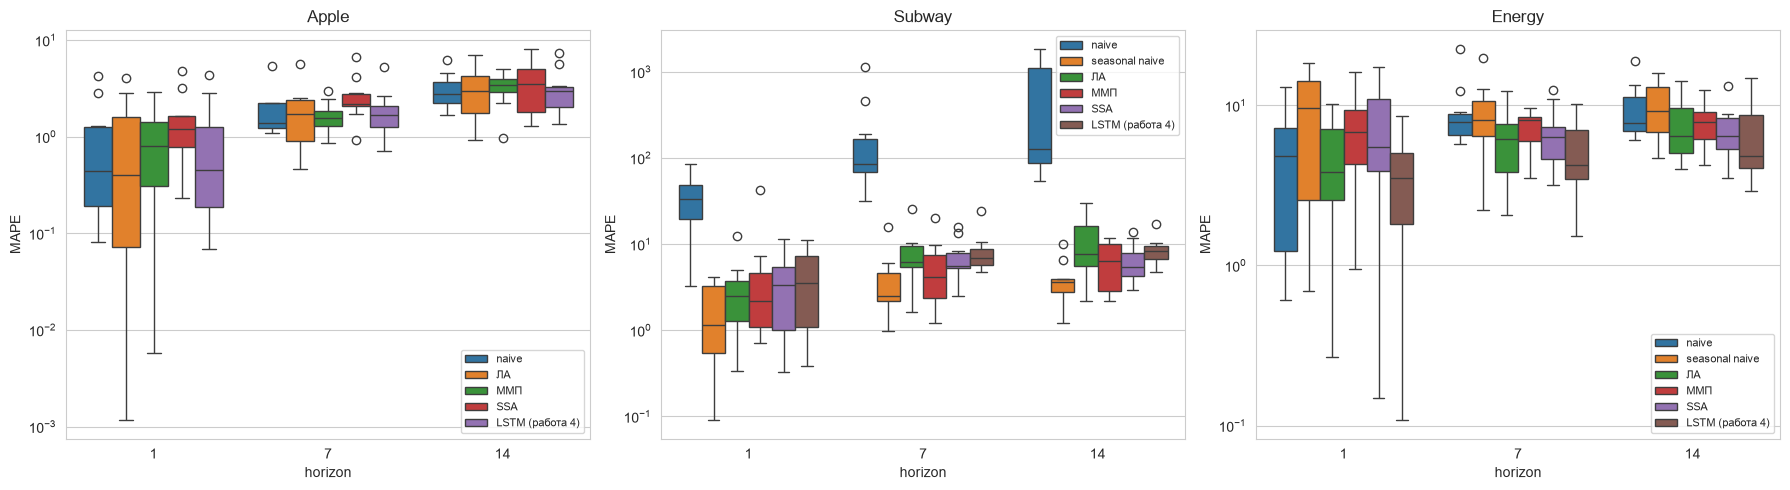

In [22]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for ax, name in zip(axes, FC_SERIES):
    sns.boxplot(data=res[res.series == name], x="horizon", y="MAPE", hue="model",
                hue_order=[v for v in VARIANTS if (res[res.series == name].model == v).any()], ax=ax)
    ax.set_yscale("log"); ax.legend(fontsize=8); ax.set_title(name)
plt.tight_layout(); plt.show()

* Разброс по 10 блокам большой, у многих методов ящики перекрываются, поэтому разницу медиан меньше 0.5-1 п.п. нельзя считать значимой
* **Apple** На h=1 все методы, кроме SSA, перекрываются почти полностью, нижние усы уходят до 0.001-0.01%, в спокойные дни цена почти не меняется. SSA и ММП стабильно выше naive
* **Метро** На h=7 и 14 ящик seasonal naive ниже и уже остальных - выигрыш устойчивый, а не за счет пары удачных блоков. naive (без сезонности) на порядок хуже всех, при прогнозе на часы вперед он бесполезен
* **Энергия** На h=1 ящики очень широкие (от долей процента до 10-15%): ошибка в первую очередь зависит от того, попал ли блок на резкую смену погоды. У LSTM ящик ниже на всех горизонтах

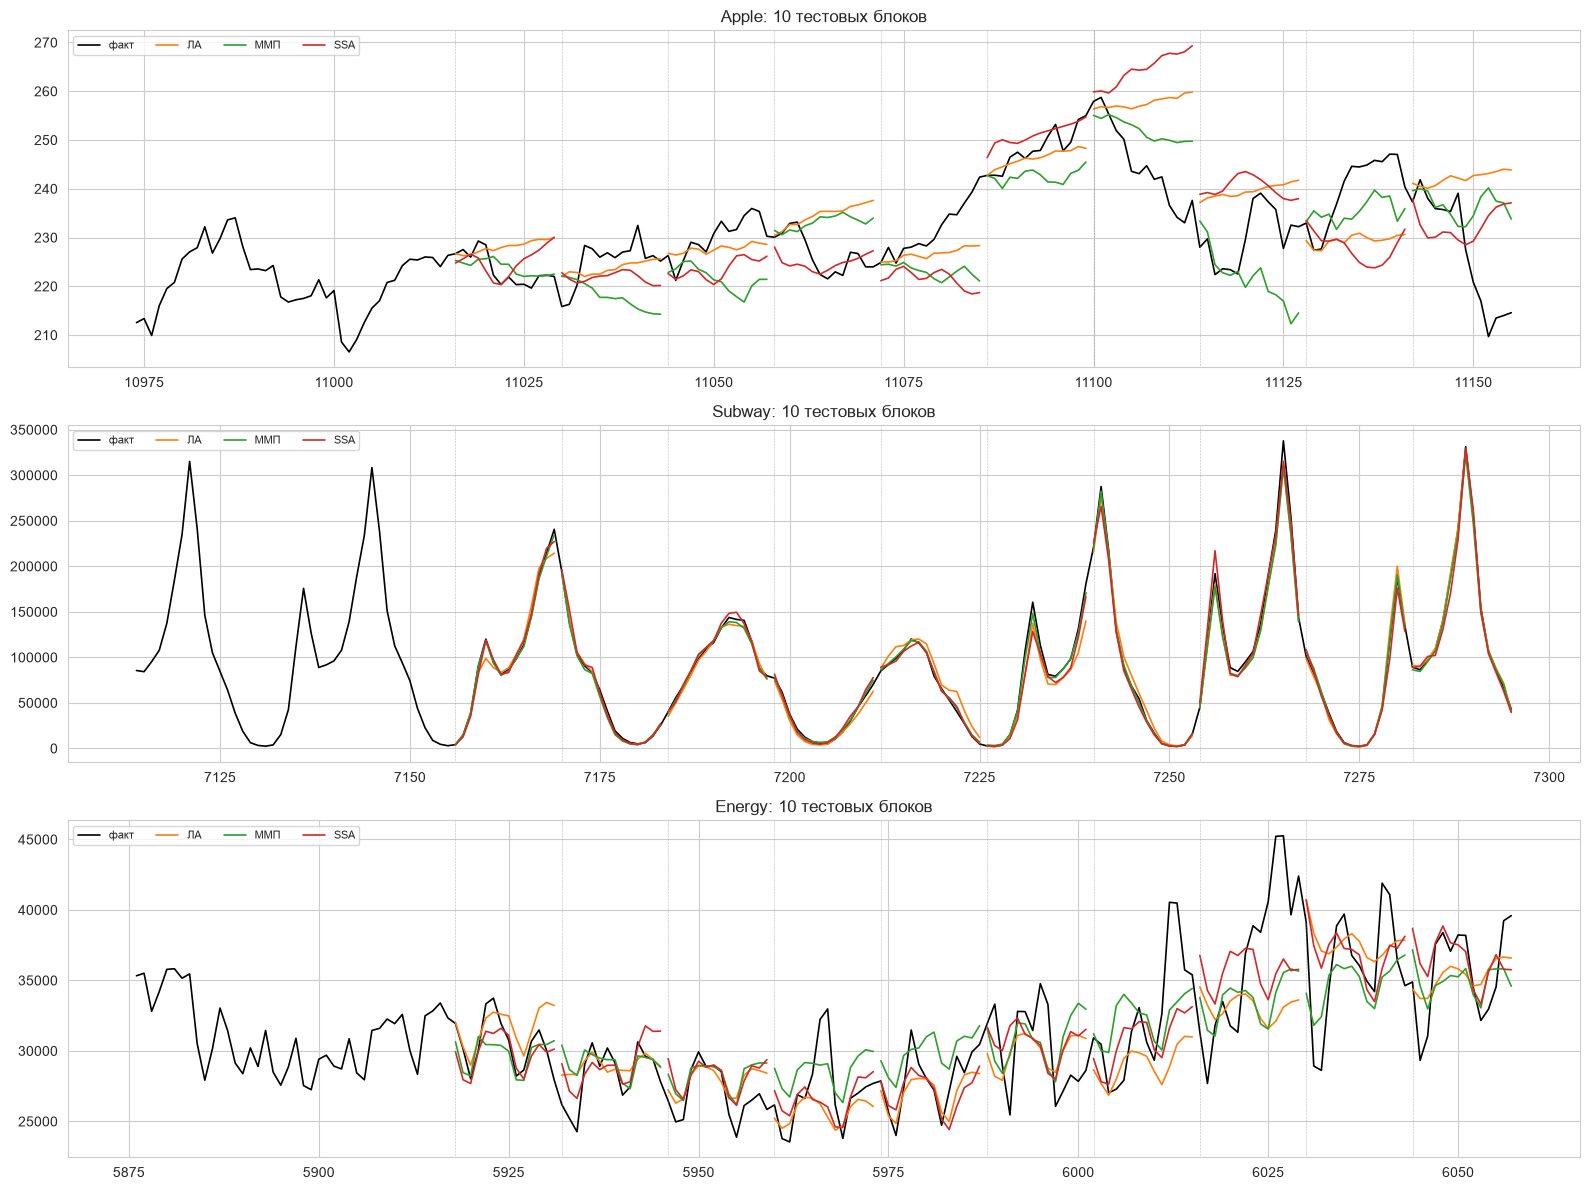

In [23]:
fig, axes = plt.subplots(3, 1, figsize=(16, 12))
for ax, name in zip(axes, FC_SERIES):
    x, O = FC_SERIES[name], ORIGINS[name]
    seg = slice(O[0] - 3 * H_MAX, O[-1] + H_MAX)
    ax.plot(np.arange(len(x))[seg], x[seg], "k", lw=1.2, label="факт")
    for i, mname in enumerate(["ЛА", "ММП", "SSA"]):
        for j, o in enumerate(O):
            ax.plot(np.arange(o, o + H_MAX), FCST[name, mname][j], color=f"C{i + 1}", lw=1.2,
                    label=mname if j == 0 else None)
    for o in O:
        ax.axvline(o, color="gray", lw=0.4, ls=":")
    ax.set_title(f"{name}: 10 тестовых блоков"); ax.legend(fontsize=8, ncol=4)
plt.tight_layout(); plt.show()

* **Apple** Методы продолжают локальный тренд. Пока цена растет, это работает (блоки 11085-11100), но на развороте у 11100 ЛА и особенно SSA продолжают рост до 260-270, а цена падает. SSA с коротким окном L=20 фактически линейно экстраполирует последние дни, поэтому ошибается сильнее всех. Падение в последнем блоке (до 210) не видит ни один метод
* **Метро** Прогнозы всех трех методов почти лежат на факте, что профиль суток и вечерние пики повторяются. Ошибки - в высоте отдельных пиков (SSA и ЛА местами завышают пик на 10-20%)
* **Энергия** Прогнозы повторяют недельный ход и общий уровень, но не ловят погодные выбросы (пик около 45 тыс. МВт в конце теста не предсказал ни один метод). SSA в некоторых блоках уходит в сторону от факта (например, в блоке около 5935 прогноз растет, а потребление падает)

# Выводы

* Все три метода прогнозируют «по аналогии с прошлым» и работают тем лучше, чем регулярнее ряд
* **Метро** (детерминированный цикл): все три метода точнее LSTM, лучший на h = 1–7 - ММП, на h = 14 - SSA. Но seasonal naive (неделя назад) обыгрывает всех
* **Энергия** (сезонность и погодный шум): лучший из трех - ЛА, SSA близок на длинных горизонтах, ММП на уровне naive. LSTM точнее всех
* **Apple** (случайное блуждание): ни один метод не лучше naive, повторяющихся состояний в ряде нет
* **ЛА** - самый универсальный: для гладких рядов первая степень и итерационный прогноз, для шумных нулевая степень и прямой прогноз
* **ММП** - самый простой (один параметр M), хорош при почти точных повторах, на шуме ненадежен; усреднение по нескольким выборкам помогает
* **SSA** - лучший для разбора структуры ряда (гармоники, тренд, шум) и для длинных горизонтов на периодических рядах
* Методы не требуют обучения, прогноз занимает миллисекунды, а оценки размерности вложения дают только нижнюю границу для p